# Core Workflow: Xenium Analysis with astrolabe

This notebook covers the standard end-to-end pipeline: load → inspect → QC/filter → normalize → visualize → spatial graph → cluster/embed → marker genes → annotate → save.

Dataset: `ab.datasets.xenium()`, the 10x Genomics Human Lung Cancer FFPE dataset (~5 GB total: 6 expression files ~254 MB + morphology OME-TIFF ~4.8 GB; ~162k cells, 377-gene panel). The download happens once and is cached locally.

Every other notebook in this library covers one specific topic in depth — spatial statistics, neighborhood analysis, images, segmentation, trajectories, BANKSY, multi-sample, other platforms.

In [1]:
import logging
logging.basicConfig(level=logging.INFO)

import numpy as np
import astrolabe as ab

## 1. Load & inspect

`ab.datasets.xenium()` downloads (once) and loads the dataset, returning a `MuData` with a `'xenium'` modality. The download is ~5 GB total (6 expression files + a morphology OME-TIFF); subsequent calls use the local cache. Internally it calls `ab.io.read_xenium(path, morphology_image=True)`.

In [2]:
mdata = ab.datasets.xenium()

# ab.summary() is the fastest way to get oriented: cell/gene counts, spatial
# extent, library info, and which obs columns are already populated.
ab.summary(mdata)

INFO:astrolabe.io._xenium:Reading Xenium run 'outs' from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\xenium_ffpe\outs


C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\anndata\utils.py:362: ExperimentalFeatureWarning: Support for Awkward Arrays is currently experimental. Behavior may change in the future. Please report any issues you may encounter!
  warnings.warn(msg, category, stacklevel=stacklevel)


INFO:astrolabe.io._xenium:Attached morphology image from morphology.ome.tif: 8 level(s), shape=(11, 17098, 51187), pixel_size=0.2125 µm


INFO:astrolabe.io._xenium:Loaded 162254 cells × 541 features (164 control probes)


INFO:astrolabe.io._xenium:Streaming transcripts from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\xenium_ffpe\outs\transcripts.parquet


INFO:astrolabe.io._xenium:Loaded 10606835 transcript detections


MuData Summary
==================================================
Modalities:
  xenium (default): 162,254 cells × 541 vars, 164 control probes
Extent: x=[113, 10873] µm  y=[92, 3608] µm
Libraries (1):
  outs: C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\xenium_ffpe\outs  (1 image(s))
Stats: mean area=72.6 µm²
Obs columns:
  QC: cell_area, nucleus_area, transcript_counts
  Other: control_probe_counts, control_codeword_counts
Graph/seg: cell_boundaries, nucleus_boundaries

Key schema fields:

- `mdata['xenium'].obsm['spatial']` — `(n_cells, 2)` float32 array, **microns**, `[x, y]`. Every spatial function in astrolabe assumes this unit and layout.
- `mdata['xenium'].obsm['cell_boundaries']` — an *awkward array* (not a regular numpy array) of one variable-length polygon per cell; cell vertex counts differ.
- `mdata['xenium'].var['is_control_probe']` — Xenium panels include negative-control and unassigned-codeword probes in `X`. They are flagged, not removed, so QC metrics can be computed on the full panel before filtering.
- `mdata.uns['default_modality']` — set to `'xenium'` automatically by the loader.

In [3]:
xen = mdata['xenium']
print(f"is_control_probe: {xen.var['is_control_probe'].sum()} of {xen.n_vars} vars flagged as controls")
xen.obs[['cell_area', 'nucleus_area', 'transcript_counts']].head()

is_control_probe: 164 of 541 vars flagged as controls


,cell_area,nucleus_area,transcript_counts
cell_id,,,
aaaadpbp-1,68.456877,NaN,0
aaaaficg-1,49.130002,21.268595,19
aaabbaka-1,119.618911,74.778753,53
aaabbjoo-1,94.241097,59.109533,29
aaablchg-1,120.341411,52.426408,42


Every astrolabe function accepts either a `MuData` or an explicit `AnnData` modality. The `@with_adata` decorator resolves `MuData` → the correct `AnnData` via `mdata.uns['default_modality']` (or an explicit `modality=` kwarg). These three calls are equivalent:

```python
ab.pp.calculate_qc_metrics(mdata)                     # resolves via uns['default_modality']
ab.pp.calculate_qc_metrics(mdata['xenium'])            # explicit AnnData
ab.pp.calculate_qc_metrics(mdata, modality='xenium')   # explicit modality
```

`mdata` is used from here on.

## 2. QC & filtering

Raw Xenium data contains segmentation artifacts, empty-polygon cells, and high-noise observations. QC metrics expose these distributions so thresholds can be chosen empirically rather than blindly.

Two QC functions serve different purposes:
- `ab.pp.calculate_qc_metrics` — general per-cell/per-gene metrics (`total_counts`, `n_genes_by_counts`, …) applicable to any platform.
- `ab.pp.calculate_xenium_qc_metrics` — Xenium-specific probe-type breakdown (unassigned codewords, deprecated codewords, genomic controls, negative controls).

`calculate_xenium_qc_metrics` only computes metrics and flags controls — it never removes features, so all probe metrics remain available for inspection here. `ab.pipeline.filter_xenium` (below) handles actual removal via `pp.filter_genes(exclude_controls=True)`, controlled by its own `remove_controls=True` default.

In [4]:
ab.pp.calculate_xenium_qc_metrics(mdata)
ab.pp.calculate_qc_metrics(mdata)
mdata['xenium'].obs[['total_counts', 'n_genes_by_counts', 'pct_counts_control']].describe()

INFO:astrolabe.pp._qc:flag_controls: 164 / 541 features flagged as controls; obs['pct_counts_control'] computed (median 0.00%, max 50.00%)


,total_counts,n_genes_by_counts,pct_counts_control
count,162254.000000,162254.000000,162254.000000
mean,56.601189,30.209530,0.018750
std,42.425991,15.084025,0.353244
min,0.000000,0.000000,0.000000
25%,27.000000,19.000000,0.000000
50%,46.000000,29.000000,0.000000
75%,75.000000,40.000000,0.000000
max,549.000000,119.000000,50.000000


Plot the distributions before picking thresholds. `pl.*_histogram()` functions (and most of `pl`) return a lazy `SpatialPanel`/`FigurePanel` — nothing renders until `.show()` is called, or until Jupyter's repr triggers it. This laziness enables `+` (overlay) and `|` (side-by-side) composition before anything is drawn.

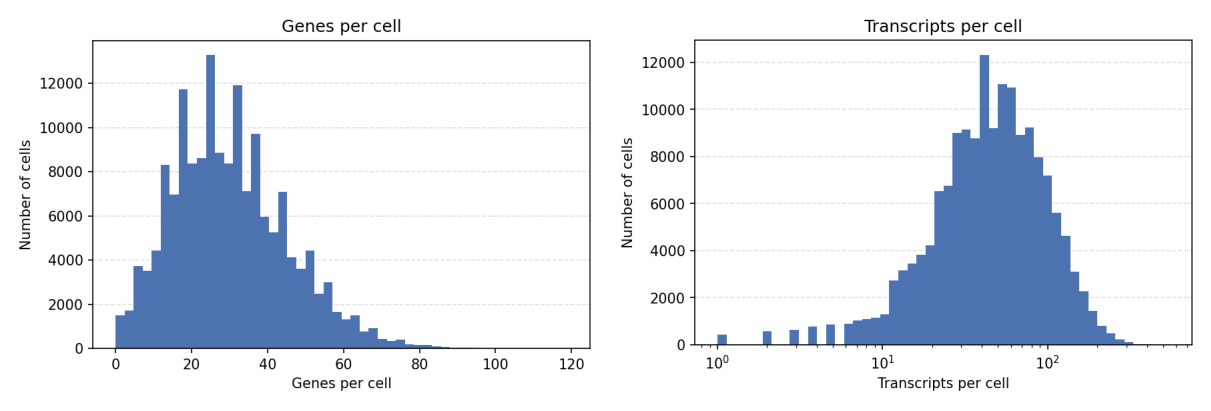

In [5]:
# `|` places two panels side by side without rendering either one individually first.
(ab.pl.genes_per_cell_histogram(mdata) | ab.pl.transcripts_per_cell_histogram(mdata)).show()

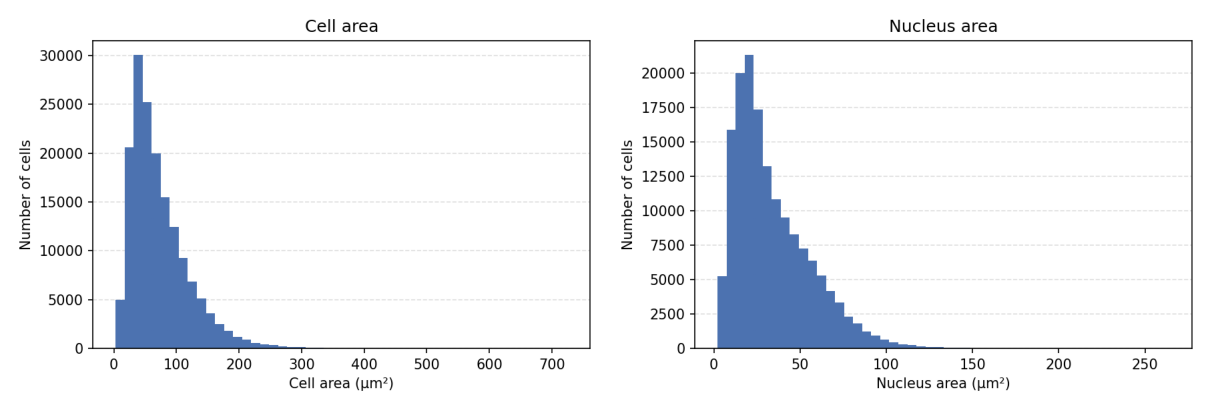

In [6]:
# Cell and nucleus area distributions — useful for spotting over/under-segmented cells
# and for deciding whether normalize_by_area is warranted.
(ab.pl.cell_area_histogram(mdata) | ab.pl.nucleus_area_histogram(mdata)).show()

In [7]:
# Quality-vs-abundance: do low-confidence probes (low mean QV) correlate with low counts?
ab.pl.gene_qv_scatter(mdata).show()

`ab.pipeline.filter_xenium` is the recommended single entry point for Xenium QC: it runs `calculate_xenium_qc_metrics` (idempotently), filters cells/genes, and removes spatially isolated cells, logging the cell count at each step.

In [8]:
n_before = mdata['xenium'].n_obs
ab.pipeline.filter_xenium(mdata, min_counts=10, min_genes=5, max_pct_control=10.0)
print(f"{n_before} -> {mdata['xenium'].n_obs} cells")

INFO:astrolabe.pipeline:filter_xenium: 162254 cells × 541 genes


INFO:astrolabe.pipeline:  calculate_xenium_qc_metrics


INFO:astrolabe.pp._qc:flag_controls: 164 / 541 features flagged as controls; obs['pct_counts_control'] computed (median 0.00%, max 50.00%)


INFO:astrolabe.pipeline:filter_cells: 162254 cells × 541 genes


INFO:astrolabe.pp._qc:filter_cells: removing 7785 / 162254 cells


...

INFO:astrolabe.pipeline:filter_cells: done — 154270 cells × 445 genes


INFO:astrolabe.pp._qc:filter_genes: removing 68 / 445 features


INFO:astrolabe.pipeline:  [remove_controls] 445 → 377 genes  (removed 68, 15.3%)


INFO:astrolabe.pipeline:filter_xenium: done — 154270 cells × 377 genes


162254 -> 154270 cells


To customize the recipe — retaining control probes for a specific QC step, or using a different isolation radius — the underlying building blocks are available individually: `pp.filter_cells`, `pp.filter_genes(exclude_controls=True)`, `pp.filter_isolated`, `pp.flag_controls`.

## 3. Normalization

Cell size correlates with transcript capture: larger cells accumulate more counts independent of transcriptional state. Two normalization strategies differ in what they correct for:

- `pp.normalize_total` — library-size normalization (scale each cell to a common total). The standard scanpy convention.
- `pp.normalize_by_area` — scales by segmented cell area in µm². More appropriate for spatial data where "library size" is partly a function of how much cell polygon was captured.

The comparison below plots both for `EPCAM`: a residual slope against cell area in the left panel indicates an uncorrected size effect.

> **GPU acceleration:** call `ab.use_gpu(True)` once before this section and normalization, PCA, UMAP, and clustering will automatically route through `rapids-singlecell` (`uv add rapids-singlecell-cu12` or `-cu13`).

In [9]:
ab.pp.normalize_total(mdata)
ab.pp.log1p(mdata)

# normalize_by_area must run after normalize_total + log1p (it expects log-space
# input). Write the area-corrected values into a separate layer rather than
# overwriting X, purely so we can compare the two side by side below.
ab.pp.normalize_by_area(mdata, layer_added='area_norm')

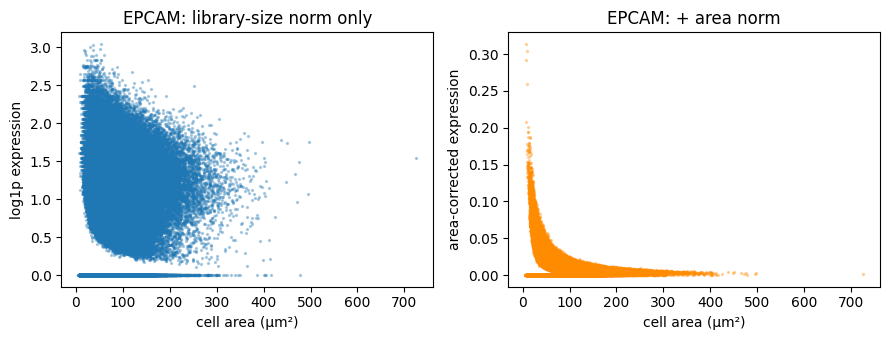

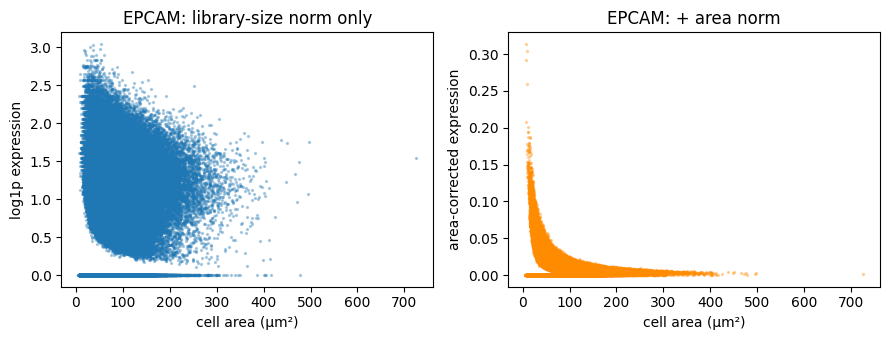

In [10]:
import matplotlib.pyplot as plt

xen = mdata['xenium']
gene = 'EPCAM' if 'EPCAM' in xen.var_names else xen.var_names[0]
g_idx = xen.var_names.get_loc(gene)

before = np.asarray(xen.X[:, g_idx].todense()).ravel() if hasattr(xen.X, 'todense') else xen.X[:, g_idx]
after = np.asarray(xen.layers['area_norm'][:, g_idx].todense()).ravel() if hasattr(xen.layers['area_norm'], 'todense') else xen.layers['area_norm'][:, g_idx]

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].scatter(xen.obs['cell_area'], before, s=2, alpha=0.3)
axes[0].set(title=f'{gene}: library-size norm only', xlabel='cell area (µm²)', ylabel='log1p expression')
axes[1].scatter(xen.obs['cell_area'], after, s=2, alpha=0.3, color='darkorange')
axes[1].set(title=f'{gene}: + area norm', xlabel='cell area (µm²)', ylabel='area-corrected expression')
fig.tight_layout()
fig

In this dataset the left panel shows a visible positive slope — EPCAM expression rises with cell area even after library-size normalization — which area normalization (right panel) substantially reduces. In practice, most downstream analyses use library-size-normalized `X` because that is the scanpy-conventional input for PCA, clustering, and differential expression; the `area_norm` layer is most useful for spatially-resolved intensity comparisons (e.g., correlating with morphology channel intensities or annotating large vs. small cells).

A residual slope in the left panel indicates library-size normalization alone did not remove the size effect; area normalization corrects it at the cost of a changed scale (no longer "counts per N transcripts"). The downstream pipeline uses library-size-normalized `X` (the scanpy-conventional choice) since `tl.cluster`/`tl.rank_genes_groups` expect that scale.

Flagging highly variable genes enables downstream PCA to optionally subset to them. `pl.mean_variance_plot` confirms HVGs sit above the mean-variance trend rather than simply tracking highest expression.

In [11]:
ab.pp.highly_variable_genes(mdata, n_top_genes=2000)
ab.pl.mean_variance_plot(mdata).show()
print(f"{mdata['xenium'].var['highly_variable'].sum()} highly variable genes flagged")

C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\pp\_normalize.py:281: UserWarning: `flavor='seurat_v3'` expects raw count data, but non-integers were found.
  return sc.pp.highly_variable_genes(


377 highly variable genes flagged


All 377 non-control genes are flagged as highly variable — expected for a targeted Xenium panel where genes were pre-selected for biological relevance and nearly all show meaningful variance across the tissue. HVG flagging here is informational rather than filtering; PCA will use the same 377 genes regardless. The `UserWarning` about non-integer data is harmless: `seurat_v3` flavor expects raw counts, but the result is unchanged because all genes pass the threshold anyway. For panels with thousands of genes (e.g., Xenium 5k), HVG selection genuinely reduces dimensionality and suppresses noisy lowly-expressed features.

## 4. Visualization basics

Before committing to a clustering resolution, look at the tissue directly: total counts for density artifacts, boundary polygons layered on expression, and a plain matplotlib figure placed alongside an astrolabe panel. The three examples below cover both composition operators (`+` for overlay, `|` for side-by-side) that recur throughout the rest of this notebook series.

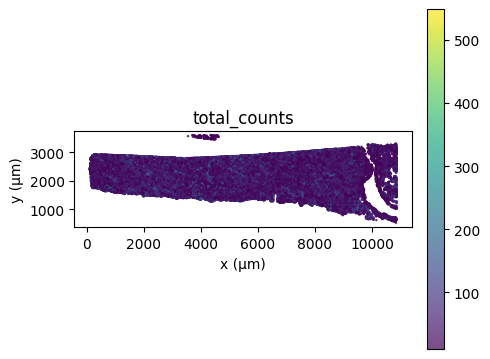

In [12]:
# Cell centroids colored by total transcript counts — reveals density/structure.
ab.pl.points(mdata, color='total_counts').show()

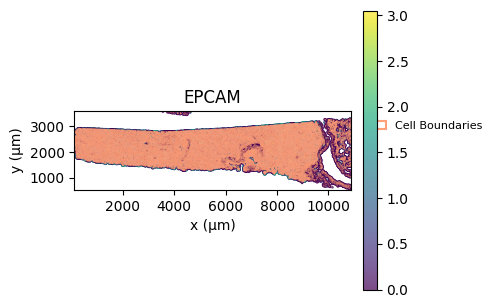

In [13]:
# Layer actual cell boundary polygons on top with `+` — both layers share one axes.
(ab.pl.points(mdata, color=gene) + ab.pl.boundaries(mdata, alpha=0.3)).show()

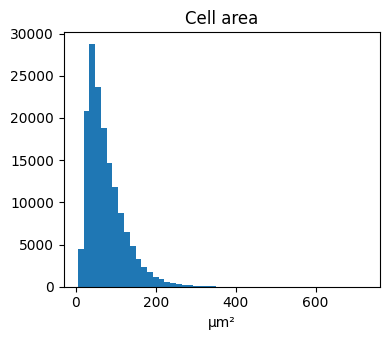

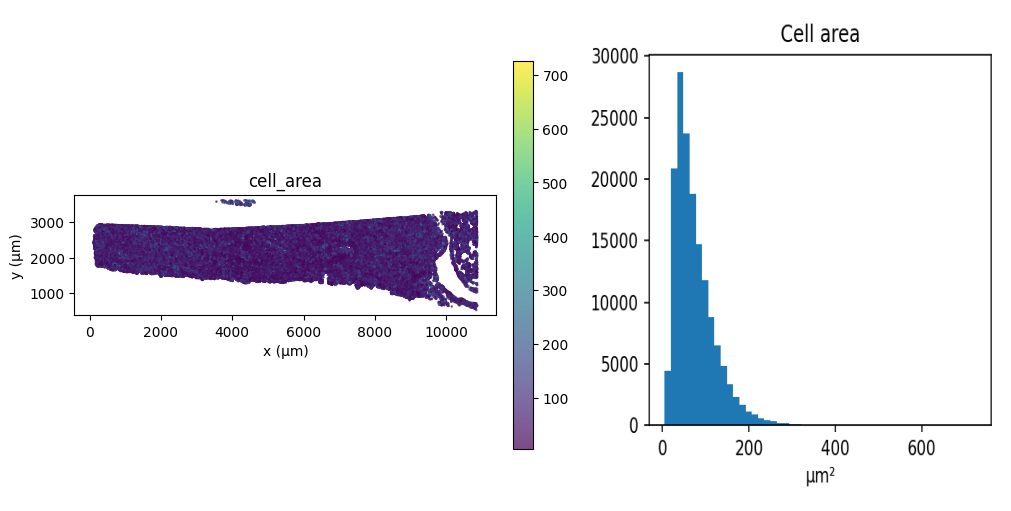

In [14]:
# A plain matplotlib figure composes too -- `|`/`/` auto-wrap a Figure or Axes,
# so you can drop a custom plot next to an astrolabe one without ceremony.
fig, ax = plt.subplots(figsize=(4, 3.5))
ax.hist(mdata['xenium'].obs['cell_area'], bins=50)
ax.set(title='Cell area', xlabel='µm²')
fig.tight_layout()

(ab.pl.points(mdata, color='cell_area') | fig).show()

### Morphology image overlay

`ab.datasets.xenium()` includes the instrument's morphology OME-TIFF, the fluorescence image used for cell segmentation. It is already in the same coordinate frame as the transcript data, so boundaries can be overlaid immediately without registration. `pl.image` auto-selects a downsampled pyramid level for rendering; `+` layers boundaries on top using the same µm coordinate system.

INFO:astrolabe.pp._transform:crop: keeping 3494 / 154270 cells inside region.


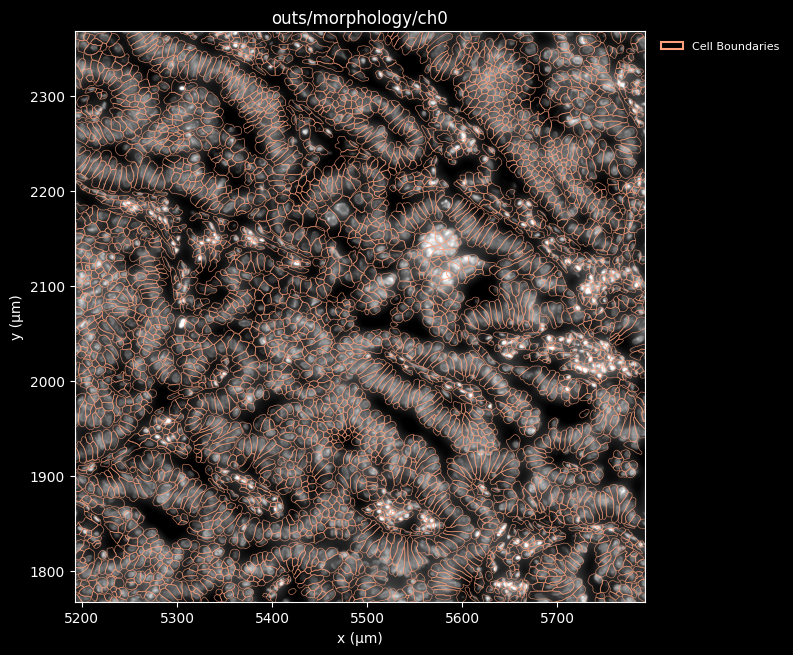

In [15]:
# Crop to a 600 µm × 600 µm sub-region for fast rendering of the morphology image.
# The full tissue is ~11000 × 3600 µm; cropping keeps the render under a second.
spatial = mdata['xenium'].obsm['spatial']
morph_center = tuple((spatial.min(axis=0) + spatial.max(axis=0)) / 2)
morph_crop_rect = ab.pl.rectangle(morph_center, 600.0, 600.0)
morph_crop = ab.pp.crop(mdata, morph_crop_rect, inplace=False)

# channel=0 selects the first morphology channel (DAPI/nuclear stain).
# `+` overlays boundaries on the image in the shared µm coordinate frame.
(
    ab.pl.image(morph_crop, image_key='morphology', channel=0)
    + ab.pl.boundaries(morph_crop, alpha=0.7)
).show()

## 5. Spatial graph & clustering

Cell identity is defined transcriptomically, not spatially, so clustering runs on an expression neighbor graph rather than the spatial one: PCA reduces the HVG-subset expression matrix, `sc.pp.neighbors` builds a transcriptomic graph, and Leiden clustering partitions it into discrete populations. `tl.pca` auto-restricts to `var['highly_variable']` when present.

**`tl.cluster` and `tl.umap` default to `neighbors_key='spatial_neighbors'`**, not the transcriptomic graph `sc.pp.neighbors` builds (`'neighbors'`). For expression-based clusters, pass `neighbors_key='neighbors'` explicitly.

In [16]:
import scanpy as sc

ab.tl.pca(mdata)
sc.pp.neighbors(mdata['xenium'])  # transcriptomic graph -> uns['neighbors']
ab.tl.cluster(mdata, resolution=0.5, neighbors_key='neighbors')
ab.tl.umap(mdata, neighbors_key='neighbors')

mdata['xenium'].obs['leiden'].value_counts()

C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\tl\_cluster.py:96: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(


INFO:astrolabe.tl._cluster:cluster (leiden, res=0.50): 9 clusters


leiden
0    38864
1    35555
2    21005
3    19520
4    17241
5    12347
6     7478
7     1181
8     1079
Name: count, dtype: int64

At resolution=0.5 the dataset resolves into 9 clusters spanning a 36× range in size. The two largest, clusters 0 and 1 (~25% and 23% of cells), both carry epithelial markers: EPCAM/KRT7/MYC and CYP2B6/TFPI/MALL. Cluster 2 (TRAC/CXCR4/PTPRC) is T-cell infiltrate, clusters 3/4 (LTBP2/PDGFRB and MS4A6A/MRC1/AIF1) are stromal and myeloid, and cluster 6 (PECAM1/VWF/CD93) is endothelial. The two small clusters, 7 (SNTN/C20orf85, ~1,200 cells) and 8 (KIT/CPA3/MS4A2, ~1,100 cells), are ciliated epithelial cells and mast cells respectively — genuine rare populations confirmed by highly specific markers, not clustering noise.

The same cluster labels in two coordinate systems: `pl.embedding_scatter` shows them in expression-UMAP space (where they were defined); `pl.points` shows them on the tissue. Spatial coherence in the right panel — same-colored cells co-localizing physically — indicates expression and anatomy correlate. `tl.moran`/`tl.nhood_enrichment` quantify this formally (see the spatial-statistics and neighborhood-analysis notebooks).

... storing 'feature_type' as categorical


... storing 'genome' as categorical


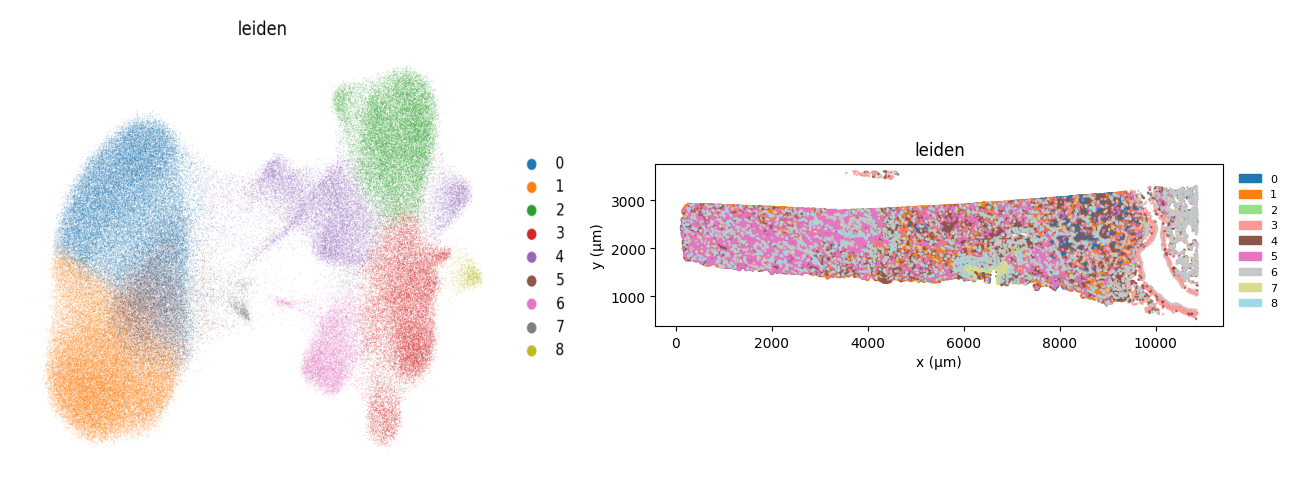

In [17]:
(ab.pl.embedding_scatter(mdata, obsm_key='X_umap', color='leiden')
 | ab.pl.points(mdata, color='leiden')).show()

With expression-based clustering complete, build the spatial neighbor graph — every spatial-statistics and neighborhood function expects one. `coord_type='generic'` (KNN/radius) is the default; `'delaunay'` gives a density-adaptive graph well-suited to variable cell density; `'grid'` is for regular spot arrays.

**`tl.spatial_neighbors` overwrites `uns['neighbors']`** with the spatial graph. Subsequent calls to `tl.cluster`/`tl.umap` with default kwargs will use the spatial graph. Re-run `sc.pp.neighbors` if a transcriptomic graph is needed afterward.

In [18]:
ab.tl.spatial_neighbors(mdata, coord_type='delaunay', delaunay_max_dist=200)

INFO:astrolabe.tl._graph:spatial_neighbors: overwriting uns['neighbors'] (previously set by sc.pp.neighbors or a prior call). Re-run sc.pp.neighbors if you need transcriptomic neighbors downstream.


INFO:astrolabe.tl._graph:spatial_neighbors: 154270 cells, 924784 edges (mean degree 6.0) [delaunay]


The Delaunay graph produces 924,784 edges with a mean degree of 6.0 — consistent with the theoretical expectation for a random planar triangulation (~6 neighbors per cell). The `delaunay_max_dist=200` µm cutoff removes spurious long edges that span empty tissue voids: at the typical Xenium cell size of 8–15 µm diameter, 200 µm corresponds to ~15–25 cell-widths, enough to bridge densely-packed tumor regions but short enough to sever edges across stromal gaps or the edges of the tissue section. Without this cutoff, a small number of very long Delaunay edges can cause global spatial statistics (Moran's I, neighborhood enrichment) to pick up tissue-boundary effects rather than local biology.

### Spatial UMAP: blending expression and tissue position

`tl.spatial_umap` produces an embedding that simultaneously weights the transcriptomic and spatial neighbor graphs. `alpha` controls the mix: `alpha=0` is a pure expression UMAP, `alpha=1` is a pure spatial layout, and values in between blend both. Cells that are expression-similar but physically distant pull apart at low alpha; spatially adjacent but expression-different cells are pushed together less than in a pure-expression UMAP.

`tl.spatial_neighbors` overwrote `uns['neighbors']` with the spatial graph above, so the expression graph must be restored before calling `tl.spatial_umap`, which needs both simultaneously.

INFO:astrolabe.tl._embedding:spatial_umap: blended graph (alpha=0.30 spatial / 0.70 expression), 4707154 non-zeros


INFO:astrolabe.tl._embedding:spatial_umap: embedding written to obsm['X_spatial_umap']


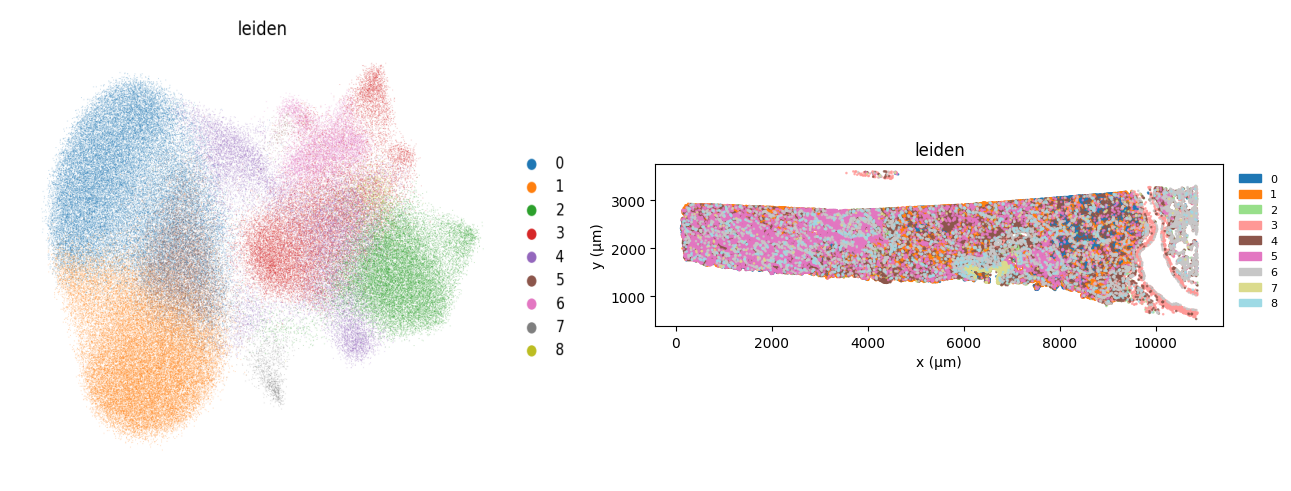

In [19]:
# Restore expression neighbors (spatial_neighbors overwrote uns['neighbors']).
sc.pp.neighbors(mdata['xenium'])
ab.tl.spatial_umap(mdata, alpha=0.3)  # 30% spatial, 70% expression

(ab.pl.embedding_scatter(mdata, obsm_key='X_spatial_umap', color='leiden')
 | ab.pl.points(mdata, color='leiden')).show()

`alpha=0.3` (30% spatial, 70% expression) is a sensible default for this dataset: the nine cluster identities are largely transcriptomically distinct (T cells vs. mast cells vs. endothelial cells), so preserving expression structure prevents spatially adjacent but biologically different clusters from collapsing together. Compare the spatial UMAP to the expression UMAP above — clusters 0 and 5 (both epithelial) move closer together in the spatial embedding because they tend to co-localize in tumor nests, while the immune cluster (2) and mast cells (8) separate further because they occupy distinct micro-anatomical compartments. For datasets where cell identity is more spatially determined than transcriptionally (e.g., developmental patterning), increasing `alpha` toward 0.7–0.9 gives a more tissue-topology-aware embedding.

## 6. Differential expression & annotation

Cluster labels are arbitrary integers until tied to genes that distinguish them. `tl.rank_genes_groups` runs one-vs-rest differential expression per cluster (wrapping `sc.tl.rank_genes_groups`) to identify each cluster's defining markers, storing results in `uns[key_added]`; `sc.get.rank_genes_groups_df` returns them as a tidy DataFrame.

In [20]:
ab.tl.rank_genes_groups(mdata, 'leiden')

de = sc.get.rank_genes_groups_df(mdata['xenium'], group=None)
top_markers = de.sort_values('scores', ascending=False).groupby('group').head(3)
top_markers

C:\Users\Austin\AppData\Local\Temp\ipykernel_2456\1726819327.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  top_markers = de.sort_values('scores', ascending=False).groupby('group').head(3)


,group,names,scores,logfoldchanges,pvals,pvals_adj
50,1,CYP2B6,268.289093,3.928156,0.0,0.0
0,0,EPCAM,202.971725,2.228669,0.0,0.0
51,1,TFPI,179.892288,2.059403,0.0,0.0
52,1,MALL,176.642105,1.948308,0.0,0.0
1,0,KRT7,165.965286,2.670675,0.0,0.0
2,0,MYC,163.477173,3.357247,0.0,0.0
100,2,TRAC,159.734192,4.510450,0.0,0.0
101,2,CXCR4,146.192535,3.695298,0.0,0.0
150,3,LTBP2,143.233521,3.634326,0.0,0.0
102,2,PTPRC,142.806686,3.358254,0.0,0.0


`pl.dotplot` visualizes the same top markers across all clusters at once — dot size encodes the fraction of cells expressing the gene, color encodes mean expression. A good marker shows a large, dark dot in exactly one column.

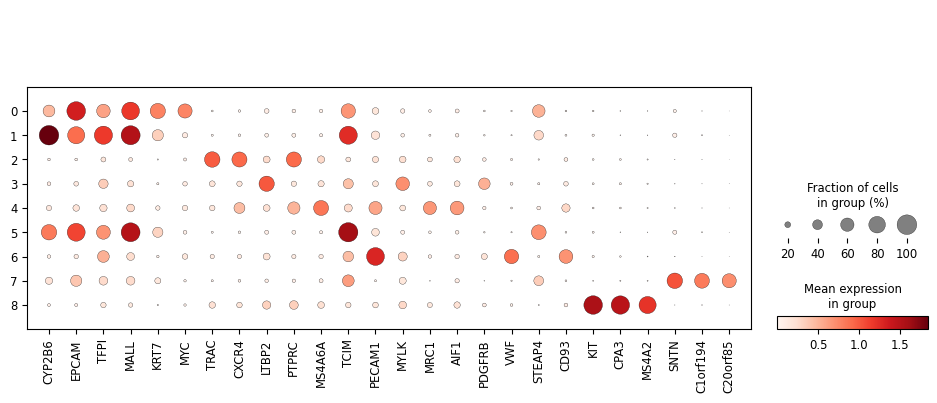

In [21]:
top_genes = top_markers['names'].unique().tolist()
ab.pl.dotplot(mdata, top_genes, groupby='leiden').show()

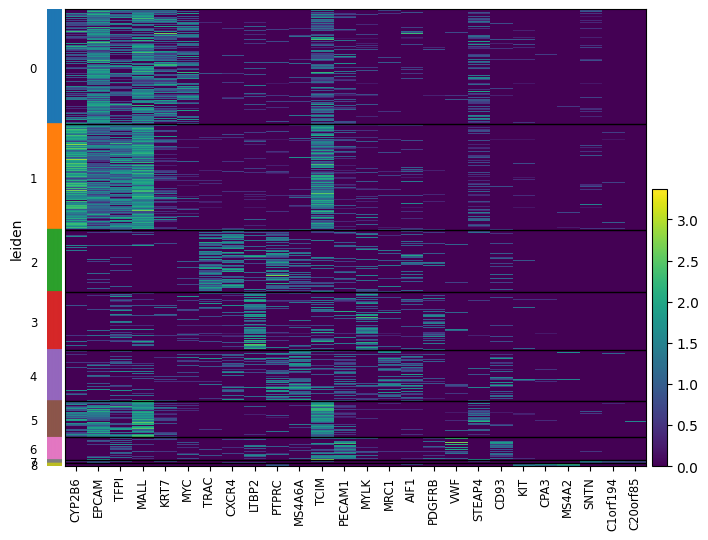

In [22]:
# Heatmap: rows are cells grouped by cluster, columns are the same top marker genes.
# Shows per-cell expression values (not cluster means), so you can see intra-cluster spread.
ab.pl.heatmap(mdata, top_genes, groupby='leiden').show()

For gene-set scoring (a curated signature rather than a single gene), `tl.score_genes` (the Seurat method: signature mean minus a matched-expression control-gene background) yields a per-cell score. As a sanity check of the method itself, cluster 0's own top markers are scored against all clusters; its own cluster should score highest.

INFO:astrolabe.tl._de:score_genes: wrote obs['signature_score']


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


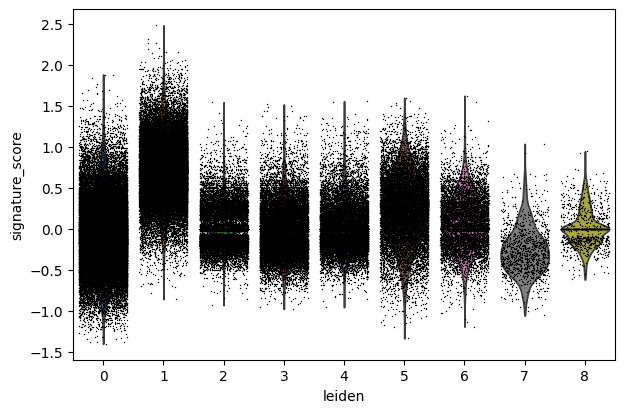

In [23]:
signature = top_markers.loc[top_markers['group'] == top_markers['group'].iloc[0], 'names'].tolist()
ab.tl.score_genes(mdata, signature, score_name='signature_score')
ab.pl.violin(mdata, 'signature_score', groupby='leiden').show()

Cluster 0's signature (EPCAM/KRT7/MYC) scores highest in cluster 0 and substantially lower in all other clusters, validating that the cluster labels reflect real transcriptional differences rather than technical variation. Clusters 1 and 5, which share epithelial character, show modestly elevated scores relative to immune and stromal clusters, consistent with shared epithelial biology. If a cluster's own top markers failed this sanity check — another cluster scoring higher — it would suggest the clustering resolution is too high and some clusters should be merged.

`tl.annotate_clusters` converts a `{cluster_id: label}` dict into an `obs` column in one call. This lung cancer dataset has established biology (EPCAM-high tumor epithelium, PTPRC-high immune infiltrate, VWF-high endothelium), but cell-type assignment requires domain expertise. As a stand-in, clusters are labeled by their top marker gene.

C:\Users\Austin\AppData\Local\Temp\ipykernel_2456\907707247.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  top_gene_per_cluster = top_markers.sort_values('scores', ascending=False).groupby('group').first()['names']
INFO:astrolabe.tl._de:annotate_clusters: wrote obs['cell_type'] — 154270 annotated, 0 'unknown'


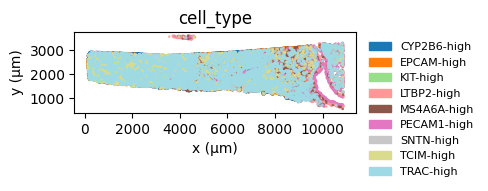

In [24]:
top_gene_per_cluster = top_markers.sort_values('scores', ascending=False).groupby('group').first()['names']
annotation = {cl: f"{gene}-high" for cl, gene in top_gene_per_cluster.items()}

ab.tl.annotate_clusters(mdata, 'leiden', annotation, key_added='cell_type')
ab.pl.points(mdata, color='cell_type').show()

## 7. Persistence

All of the above — QC metrics, normalization, clusters, embeddings, the spatial graph, cell-type labels — lives in one `MuData` object. `io.save`/`io.load` round-trip it to a single `.h5mu` file so you don't have to redo any of it next time, including the `ImageSpec` objects and awkward boundary arrays that plain `mudata.write` can't handle on its own.

In [25]:
out_path = '.astrolabe_cache/datasets/xenium_ffpe/processed'
ab.io.save(mdata, out_path, overwrite=True)

mdata_reloaded = ab.io.load(out_path + '.h5mu')
ab.summary(mdata_reloaded)

INFO:astrolabe.io._io:save: wrote .astrolabe_cache\datasets\xenium_ffpe\processed.h5mu


INFO:astrolabe.io._io:load: reading .astrolabe_cache\datasets\xenium_ffpe\processed.h5mu


INFO:astrolabe.io._io:load: done — 154270 cells


MuData Summary
==================================================
Modalities:
  xenium (default): 154,270 cells × 377 vars
Extent: x=[113, 10871] µm  y=[530, 3605] µm
Libraries (1):
  outs: C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\xenium_ffpe\outs  (1 image(s))
Stats: median counts=48, median genes=29, mean area=74.5 µm²
Features: 377 HVGs
Clustering:
  leiden: 9 clusters
Obs columns:
  QC: cell_area, nucleus_area, transcript_counts, unassigned_codeword_total, deprecated_codeword_total, genomic_control_probe_total, negative_control_codeword_total, negative_control_probe_total, any_negative_control_probe_total, n_unassigned_codewords, n_deprecated_codewords, n_genomic_control_probes, n_negative_control_codewords, n_negative_control_probes, n_any_negative_control_probes, pct_unassigned_codewords, pct_deprecated_codewords, pct_genomic_control_probes, pct_negative_control_codewords, pct_negative_control_probes, pct_any_negative_control_probes, pct_counts_control, n_genes_by_counts, log1p_n_genes_by_counts, total_counts, log1p_total_counts, pct_counts_in_top_50_genes, pct_counts_in_top_100_genes, pct_counts_in_top_200_genes, pct_counts_in_top_500_genes, nucleus_to_cell_area_ratio, has_nucleus
  Clustering: leiden
  Gene scores: signature_score
  Other: control_probe_counts, control_codeword_counts, total_counts_norm, cell_type
Graph/seg: cell_boundaries, nucleus_boundaries, spatial_graph
Workflow: QC → Normalized → log1p → HVGs → PCA → Clustered

## Where to go next

This notebook covered the standard path: load, QC, normalize, visualize, cluster, annotate, save. Each subsequent notebook in this library explores one topic in depth:

- *Quantifying spatial organization gene by gene* → `02_spatial_statistics.ipynb`
- *Cell-type adjacency and whether contact changes biology* → `03_neighborhood_analysis.ipynb`
- *Protein (IF) or H&E imagery* → `04_if_and_he_images.ipynb`
- *Cropping a region or replacing the shipped segmentation* → `05_segmentation_and_crop.ipynb`
- *Continuous cell states and spatially co-varying gene programs* → `06_trajectory_and_gene_modules.ipynb`
- *Clustering that bakes spatial context into the input* → `07_banksy_spatial_domains.ipynb`
- *Working with more than one Xenium run* → `08_multi_sample_and_persistence.ipynb`
- *Applying this pipeline to MERSCOPE or CosMx data* → `09_merscope_and_cosmx.ipynb`

Each is independent and runnable from a fresh kernel.